# 14 — Regressão Linear: o Olhar Estatístico

No ML-01, a regressão linear foi um **modelo de previsão**: treinar, prever, medir o erro no teste. A estatística olha para o mesmo modelo com outras perguntas:
- **Quanto** a gorjeta aumenta, em média, por dólar de conta? E **com que incerteza**?
- Esse efeito é real ou poderia ser acaso? (um teste de hipótese para cada coeficiente)
- Que faixa de valores esperar para uma **nova** mesa? (intervalo de previsão)
- As **premissas** do modelo valem? Se não valem, o que muda?

Este notebook abre a **Parte IV (ponte para o ML)** e junta quase tudo o que vimos: esperança condicional (09), erro padrão e intervalos (10 e 11), testes (12) e máxima verossimilhança (13).

Vamos:
- Ajustar uma regressão com o **statsmodels** e ler a sua tabela de resultados
- Calcular os coeficientes e os **erros padrão** à mão e conferir com o **bootstrap**
- Interpretar uma **regressão múltipla** com variáveis categóricas
- Distinguir **intervalo de confiança** da média e **intervalo de previsão**
- Verificar as **premissas** com a análise de resíduos e usar **erros padrão robustos**
- Medir a **multicolinearidade** com o VIF

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf                               # regressões escritas como fórmulas, ao estilo "y ~ x"
from statsmodels.stats.diagnostic import het_breuschpagan            # teste de variância constante dos resíduos
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

gorjetas = sns.load_dataset("tips")
pinguins = sns.load_dataset("penguins").dropna()

## 🎓 Conceito: o modelo de regressão linear (estatístico)

O modelo supõe que, para cada observação,

$$y_i = \beta_0 + \beta_1 x_i + \varepsilon_i, \qquad \varepsilon_i \sim N(0, \sigma^2) \text{ independentes}$$

- $\beta_0 + \beta_1 x$ é a **esperança condicional** $E[Y \mid X = x]$ (notebook 09), suposta uma reta.
- $\beta_0$ e $\beta_1$ são **parâmetros** da população, que estimamos com os dados ($\hat{\beta}_0$, $\hat{\beta}_1$).
- Pelo notebook 13, o EMV com erros normais é o de **mínimos quadrados**.
- Como as estimativas vêm de uma amostra, elas têm **erro padrão**, e podemos construir intervalos de confiança e testes para elas.

O `statsmodels` faz tudo isso e apresenta numa tabela. A **fórmula** `"tip ~ total_bill"` lê-se "gorjeta explicada pela conta" (o intercepto entra automaticamente).

In [2]:
modelo = smf.ols("tip ~ total_bill", data=gorjetas).fit()   # ols = ordinary least squares (mínimos quadrados)
print(modelo.summary().tables[1])                            # a tabela dos coeficientes
print(f"\nR² = {modelo.rsquared:.4f}   σ estimado (desvio dos resíduos) = {np.sqrt(modelo.scale):.4f}   n = {int(modelo.nobs)}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9203      0.160      5.761      0.000       0.606       1.235
total_bill     0.1050      0.007     14.260      0.000       0.091       0.120

R² = 0.4566   σ estimado (desvio dos resíduos) = 1.0220   n = 244


Como ler a tabela, linha a linha (para cada coeficiente):

| Coluna | Significado |
|---|---|
| `coef` | a estimativa $\hat{\beta}$ |
| `std err` | o **erro padrão** da estimativa: quanto ela variaria de amostra para amostra |
| `t` | `coef / std err`: a quantos erros padrão a estimativa está de zero |
| `P>|t|` | p-valor do teste $H_0: \beta = 0$ ("a variável não tem efeito linear") |
| `[0.025  0.975]` | intervalo de confiança de 95% para $\beta$ |

**Conclusão:** a reta é a mesma do notebook 13: gorjeta ≈ **0,92 + 0,105 × conta**. Agora ela vem com a incerteza:
- A inclinação tem erro padrão de **0,007** e IC de 95% de **[0,091; 0,120]**: cada dólar a mais na conta acrescenta, em média, entre cerca de 9 e 12 centavos de gorjeta.
- O $t$ de **14,26** diz que a inclinação está a mais de 14 erros padrão de zero, e o p-valor é praticamente zero (a tabela mostra 0,000): não há dúvida de que existe uma relação linear.
- O $R^2$ é **0,457**, o quadrado da correlação de 0,676 do notebook 04. A conta explica cerca de 46% da variação das gorjetas.
- O desvio dos resíduos, $\hat{\sigma} = 1{,}02$, diz que uma mesa típica fica a cerca de **US\$ 1** da reta.

## 2. Por dentro da tabela: as contas à mão

Para uma única variável, as fórmulas são:

$$\hat{\beta}_1 = \frac{\text{Cov}(x, y)}{\text{Var}(x)} = r \cdot \frac{s_y}{s_x} \qquad \hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$$

$$\text{EP}(\hat{\beta}_1) = \frac{\hat{\sigma}}{\sqrt{\sum (x_i - \bar{x})^2}}, \qquad \hat{\sigma}^2 = \frac{\sum \text{resíduos}^2}{n - 2}$$

(Dividimos por $n - 2$ porque estimamos 2 parâmetros: a mesma ideia de graus de liberdade do $n - 1$ do notebook 02.) Repare na fórmula do erro padrão: ele diminui com **mais dados** e com **mais variação em $x$**. Um $x$ espalhado "segura" melhor a inclinação da reta.

Vamos conferir também com o **bootstrap** (notebook 11): reamostrar as mesas, reajustar a reta e olhar a variação da inclinação.

In [3]:
x = gorjetas["total_bill"].to_numpy()
y = gorjetas["tip"].to_numpy()
n = len(x)

b1 = np.cov(x, y)[0, 1] / np.var(x, ddof=1)
b0 = y.mean() - b1 * x.mean()
residuos = y - (b0 + b1 * x)
sigma2 = np.sum(residuos ** 2) / (n - 2)
ep_b1 = np.sqrt(sigma2 / np.sum((x - x.mean()) ** 2))
t_b1 = b1 / ep_b1
p_b1 = 2 * stats.t.sf(abs(t_b1), df=n - 2)   # bilateral: as duas caudas da t
ic_b1 = b1 + np.array([-1, 1]) * stats.t.ppf(0.975, n - 2) * ep_b1

print(f"À mão:        β1 = {b1:.4f}  EP = {ep_b1:.4f}  t = {t_b1:.2f}  p = {p_b1:.1e}  IC = [{ic_b1[0]:.4f}, {ic_b1[1]:.4f}]")
print(f"statsmodels:  β1 = {modelo.params['total_bill']:.4f}  EP = {modelo.bse['total_bill']:.4f}  t = {modelo.tvalues['total_bill']:.2f}")

# Bootstrap da inclinação: 5.000 reamostragens de mesas.
inclinacoes = []
for _ in range(5_000):
    idx = rng.integers(0, n, n)
    inclinacoes.append(np.polyfit(x[idx], y[idx], 1)[0])
inclinacoes = np.array(inclinacoes)
print(f"Bootstrap:    EP = {inclinacoes.std():.4f}  IC percentil = [{np.percentile(inclinacoes, 2.5):.4f}, {np.percentile(inclinacoes, 97.5):.4f}]")

À mão:        β1 = 0.1050  EP = 0.0074  t = 14.26  p = 6.7e-34  IC = [0.0905, 0.1195]
statsmodels:  β1 = 0.1050  EP = 0.0074  t = 14.26
Bootstrap:    EP = 0.0117  IC percentil = [0.0819, 0.1280]


**Conclusão:** as contas à mão reproduzem exatamente a tabela do statsmodels: $\hat{\beta}_1 = 0{,}1050$, EP = **0,0074** e $t = 14{,}26$, com p-valor da ordem de $10^{-34}$.

Mas o **bootstrap discorda**: ele estima um erro padrão de **0,0117**, cerca de **60% maior**, e um IC mais largo ([0,082; 0,128]). Quem está certo? A fórmula do erro padrão supõe que os erros têm a **mesma variância** para qualquer conta; o bootstrap não supõe nada disso. Essa discordância é um sinal de que uma premissa pode estar falhando, e vamos investigá-la na análise de resíduos.

## 🎓 Conceito: regressão múltipla e "mantendo o resto constante"

Com vários atributos, $y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \varepsilon$. Cada coeficiente passa a ter uma interpretação **condicional**: $\beta_1$ é a mudança média em $y$ quando $x_1$ aumenta 1 unidade **e os outros atributos ficam iguais**.

Isso muda os coeficientes. Uma variável que parecia importante sozinha pode perder o efeito quando outra, que conta a mesma história, entra no modelo (é o controle de variáveis de confusão do notebook 04).

Variáveis **categóricas** entram como colunas 0/1 (o **one-hot** do ML-02), com uma categoria de **referência** que fica de fora. Na fórmula, isso é feito automaticamente; `C(day)` força uma coluna a ser tratada como categórica.

In [4]:
simples_size = smf.ols("tip ~ size", data=gorjetas).fit()
multipla = smf.ols("tip ~ total_bill + size + C(smoker) + C(time) + C(day)", data=gorjetas).fit()

print(f"Só o tamanho da mesa:   coef de size = {simples_size.params['size']:.4f}  (p = {simples_size.pvalues['size']:.1e})\n")
# Montando uma tabela enxuta com coeficientes, ICs e p-valores.
tabela = pd.concat([multipla.params, multipla.conf_int(), multipla.pvalues], axis=1)
tabela.columns = ["coef", "IC 2,5%", "IC 97,5%", "p-valor"]
print(tabela.round(4))
print(f"\nR² = {multipla.rsquared:.4f}   R² ajustado = {multipla.rsquared_adj:.4f}   (modelo só com a conta: R² = {modelo.rsquared:.4f})")

Só o tamanho da mesa:   coef de size = 0.7118  (p = 4.3e-16)

                     coef  IC 2,5%  IC 97,5%  p-valor
Intercept          0.6103   0.1359    1.0847   0.0119
C(smoker)[T.No]    0.0865  -0.2017    0.3747   0.5550
C(time)[T.Dinner] -0.0681  -0.9423    0.8060   0.8781
C(day)[T.Fri]      0.1609  -0.6124    0.9343   0.6822
C(day)[T.Sat]      0.0351  -0.8889    0.9590   0.9404
C(day)[T.Sun]      0.1284  -0.7962    1.0530   0.7847
total_bill         0.0943   0.0755    0.1131   0.0000
size               0.1764   0.0004    0.3524   0.0495

R² = 0.4700   R² ajustado = 0.4542   (modelo só com a conta: R² = 0.4566)


**Conclusão:** sozinho, o tamanho da mesa parece ter um efeito forte: **+US\$ 0,71** de gorjeta por pessoa, com p-valor de $10^{-16}$. No modelo múltiplo, **mantendo a conta constante**, o efeito cai para **+US\$ 0,18** por pessoa, com p-valor de **0,0495**, no limite do "significativo", e um IC que vai de praticamente zero (0,0004) a 0,35. Boa parte do efeito do tamanho da mesa era, na verdade, o efeito da **conta** (mesas maiores gastam mais), uma variável de confusão.

As variáveis categóricas (fumantes, refeição e dia) têm coeficientes pequenos, ICs que incluem o zero e p-valores altos (de 0,55 a 0,94), o que é coerente com o teste do notebook 12 para os fumantes. Os ICs de refeição e dia são muito largos porque essas variáveis são quase redundantes entre si (sábado e domingo só têm jantares, notebook 04).

Acrescentar cinco variáveis subiu o $R^2$ de 0,457 para **0,470**, mas o **$R^2$ ajustado** (0,454) ficou praticamente igual ao do modelo simples: as variáveis extras quase não acrescentam informação.

## 🎓 Conceito: intervalo de confiança × intervalo de previsão

Para uma conta de US\$ 30, há duas perguntas diferentes:
1. Qual a gorjeta **média** de **todas** as mesas com conta de US\$ 30? → **intervalo de confiança da média**. Ele só reflete a incerteza sobre a **reta**, e encolhe quando $n$ cresce.
2. Qual será a gorjeta de **uma próxima** mesa com conta de US\$ 30? → **intervalo de previsão**. Ele soma a incerteza da reta com a **variação individual** de cada mesa ($\sigma$), e **nunca** encolhe abaixo disso, por mais dados que tenhamos.

🔗 **Ponte para o ML:** um modelo de ML costuma devolver só a previsão pontual. Mas, para decidir, muitas vezes precisamos da **faixa** de valores plausíveis para um caso individual: o intervalo de previsão (ou, de forma mais geral, os métodos de **previsão conformal** e a **regressão quantílica**).

    mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  4.071      0.1          3.875          4.267         2.048         6.094


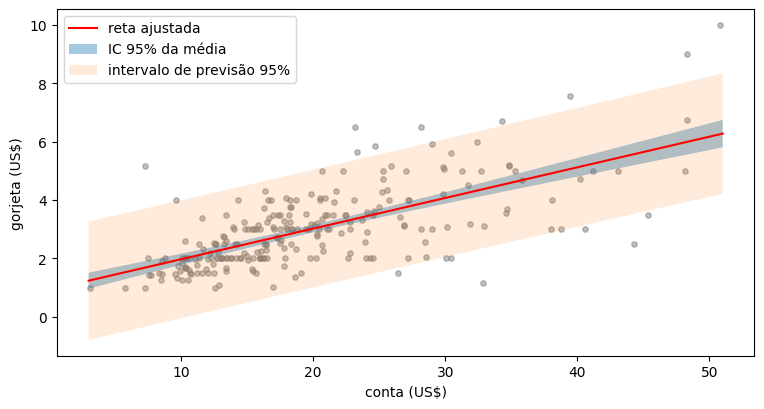


Mesas dentro do intervalo de previsão: 93.0%


In [5]:
novas = pd.DataFrame({"total_bill": np.linspace(3, 51, 100)})
previsao = modelo.get_prediction(novas).summary_frame(alpha=0.05)   # devolve a média e os dois intervalos
print(modelo.get_prediction(pd.DataFrame({"total_bill": [30]})).summary_frame(alpha=0.05).round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(gorjetas["total_bill"], gorjetas["tip"], alpha=0.5, s=15, color="gray")
ax.plot(novas["total_bill"], previsao["mean"], color="red", label="reta ajustada")
ax.fill_between(novas["total_bill"], previsao["mean_ci_lower"], previsao["mean_ci_upper"], alpha=0.4, label="IC 95% da média")
ax.fill_between(novas["total_bill"], previsao["obs_ci_lower"], previsao["obs_ci_upper"], alpha=0.15, label="intervalo de previsão 95%")
ax.set_xlabel("conta (US$)")
ax.set_ylabel("gorjeta (US$)")
ax.legend()
plt.show()

# Cobertura do intervalo de previsão nos próprios dados: que fração das mesas cai dentro dele?
dentro = modelo.get_prediction(gorjetas).summary_frame(alpha=0.05)
cobertura = np.mean((gorjetas["tip"] >= dentro["obs_ci_lower"]) & (gorjetas["tip"] <= dentro["obs_ci_upper"]))
print(f"\nMesas dentro do intervalo de previsão: {cobertura:.1%}")

**Conclusão:** para uma conta de US\$ 30, a gorjeta prevista é **US\$ 4,07**. O IC de 95% da **média** é estreito, **[3,88; 4,27]**: sabemos com boa precisão a gorjeta média de mesas assim. Mas o intervalo de **previsão** para **uma** mesa é bem mais largo, **[2,05; 6,09]**, porque mesas individuais variam muito em torno da média.

No gráfico, a faixa escura (IC da média) é fina e se alarga nas pontas, onde há menos dados; a faixa clara (previsão) é larga em toda a extensão. Nos próprios dados, **93,0%** das mesas caem dentro do intervalo de previsão, um pouco abaixo dos 95% prometidos. Repare onde ficam os pontos de fora: **15 das 17** mesas fora do intervalo têm contas acima de US\$ 20, onde a dispersão real é maior do que o modelo supõe.

## 🎓 Conceito: as premissas e a análise de resíduos

Os erros padrão, os ICs e os p-valores dependem das premissas do modelo. As principais (lembradas pela sigla **LINE**):
- **L**inearidade: a média de $y$ é mesmo uma reta em $x$.
- **I**ndependência: os erros de observações diferentes não se influenciam.
- **N**ormalidade dos erros (menos importante com amostras grandes, graças ao TCL).
- **E**qual variância (**homocedasticidade**): a dispersão dos erros é a mesma para qualquer $x$.

Elas são verificadas olhando os **resíduos**. O gráfico mais útil é **resíduos × valores previstos**: se tudo estiver bem, ele parece uma nuvem sem forma, centrada em zero e com largura constante.

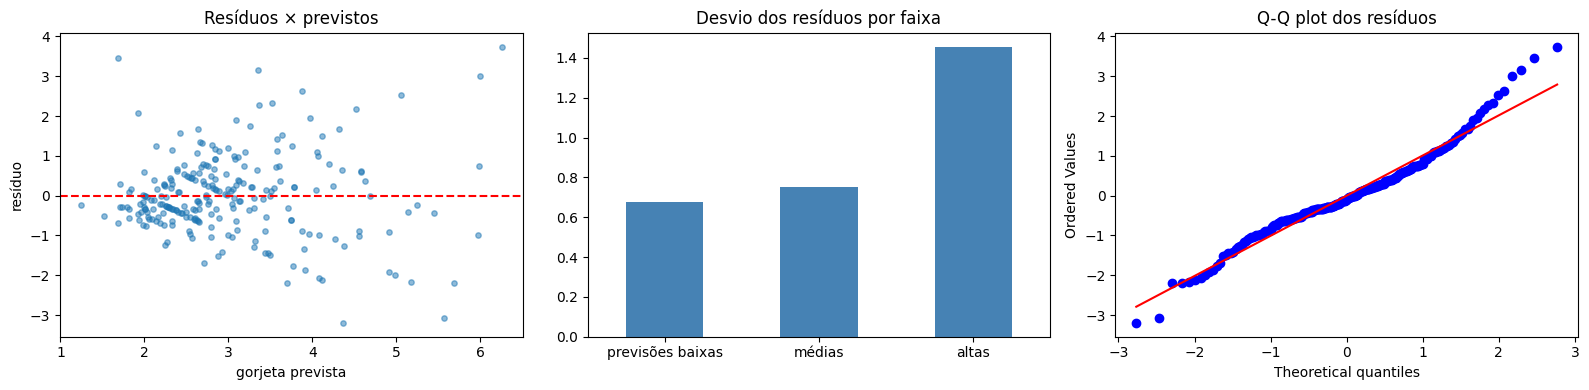

Breusch-Pagan: p-valor = 4.54e-12


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(modelo.fittedvalues, modelo.resid, alpha=0.5, s=15)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("gorjeta prevista")
axes[0].set_ylabel("resíduo")
axes[0].set_title("Resíduos × previstos")

# A "largura" dos resíduos por faixa de valor previsto: o desvio padrão dos resíduos em cada terço.
terco = pd.qcut(modelo.fittedvalues, 3, labels=["previsões baixas", "médias", "altas"])   # qcut: faixas com o mesmo número de pontos
modelo.resid.groupby(terco, observed=True).std().plot.bar(ax=axes[1], color="steelblue", rot=0)
axes[1].set_title("Desvio dos resíduos por faixa")

stats.probplot(modelo.resid, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot dos resíduos")
plt.tight_layout()
plt.show()

# Teste de Breusch-Pagan: H0 = variância constante. Ele devolve (estatística, p-valor, ...).
bp = het_breuschpagan(modelo.resid, modelo.model.exog)
print(f"Breusch-Pagan: p-valor = {bp[1]:.2e}")

**Conclusão:** a premissa de **variância constante** falha claramente:
- No gráfico de resíduos, a nuvem tem forma de **funil**: estreita para as previsões baixas e cada vez mais larga para as altas.
- O desvio dos resíduos é de **0,68** no terço das previsões baixas, 0,75 no do meio e **1,45** no das altas, mais que o dobro. Mesas com contas altas têm gorjetas muito mais variáveis.
- O teste de **Breusch-Pagan** rejeita a variância constante com folga (p-valor $\approx 4{,}5 \times 10^{-12}$).
- O Q-Q plot mostra resíduos aproximadamente normais no centro, com a cauda direita um pouco mais pesada (os maiores resíduos positivos, como a gorjeta de US\$ 10 numa conta de US\$ 50,81).

É isso que explica a discordância do bootstrap: a fórmula usual **subestimava** a incerteza da inclinação.

## 🎓 Conceito: erros padrão robustos

Quando a variância dos erros **não** é constante (**heterocedasticidade**), os coeficientes continuam bons (sem viés), mas a fórmula usual dos **erros padrão** fica errada, e com ela os ICs e p-valores. Uma correção simples são os **erros padrão robustos** (de White, também chamados de "sanduíche"; a versão HC3 é a mais recomendada): eles estimam a variação dos coeficientes sem supor variância constante.

Outra saída é **transformar** a variável: modelar o **percentual** de gorjeta, ou o log da gorjeta, costuma estabilizar a variância.

In [7]:
robusto = smf.ols("tip ~ total_bill", data=gorjetas).fit(cov_type="HC3")
comparacao = pd.DataFrame({
    "EP usual": modelo.bse,
    "EP robusto (HC3)": robusto.bse,
    "EP bootstrap": [np.nan, inclinacoes.std()],   # só calculamos o bootstrap da inclinação
})
print(comparacao.round(4))

ic_usual = modelo.conf_int().loc["total_bill"].to_numpy()
ic_robusto = robusto.conf_int().loc["total_bill"].to_numpy()
print(f"\nIC 95% da inclinação — usual: [{ic_usual[0]:.4f}, {ic_usual[1]:.4f}]   robusto: [{ic_robusto[0]:.4f}, {ic_robusto[1]:.4f}]")

            EP usual  EP robusto (HC3)  EP bootstrap
Intercept     0.1597            0.2117           NaN
total_bill    0.0074            0.0121        0.0117

IC 95% da inclinação — usual: [0.0905, 0.1195]   robusto: [0.0812, 0.1288]


**Conclusão:** o erro padrão robusto da inclinação (**0,0121**) é muito parecido com o do bootstrap (**0,0117**), e os dois são cerca de 60% maiores que o usual (0,0074). Duas abordagens independentes, que não supõem variância constante, concordam entre si. O IC robusto, **[0,081; 0,129]**, é mais largo que o usual, mas a conclusão principal continua de pé: a gorjeta cresce com a conta, entre ~8 e ~13 centavos por dólar.

Lição: quando a variância não é constante, a **estimativa** do coeficiente continua boa, mas a fórmula usual deixa o modelo **confiante demais**. Com dados reais, usar erros padrão robustos é uma escolha prudente.

## 🎓 Conceito: multicolinearidade e o VIF

Quando dois atributos são **muito correlacionados**, o modelo não consegue separar o efeito de cada um: muitas combinações de coeficientes explicam os dados quase igualmente bem. Os coeficientes ficam **instáveis** e com erros padrão enormes (foi o problema dos cômodos e quartos no ML-01).

O **VIF** (fator de inflação da variância) mede isso para cada atributo: é quanto a variância do seu coeficiente aumenta por causa da correlação com os outros. Ele é calculado regredindo o atributo nos demais: $\text{VIF} = 1 / (1 - R^2)$. Regra prática: VIF acima de **5 a 10** merece atenção.

Vamos prever a massa dos pinguins **Gentoo** com as medidas do corpo, e depois incluir uma variável quase redundante: a nadadeira medida em **centímetros arredondados**, com um pequeno erro de medida.

In [8]:
gentoo = pinguins[pinguins["species"] == "Gentoo"].copy()
gentoo["flipper_cm"] = (gentoo["flipper_length_mm"] / 10 + rng.normal(0, 0.1, len(gentoo))).round(1)

def tabela_vif(dados, colunas):
    """VIF de cada coluna, com uma coluna constante para o intercepto."""
    X = dados[colunas].assign(constante=1.0).to_numpy()
    return pd.Series([variance_inflation_factor(X, i) for i in range(len(colunas))], index=colunas)

colunas = ["flipper_length_mm", "bill_length_mm", "bill_depth_mm"]
print("VIF sem a variável redundante:\n", tabela_vif(gentoo, colunas).round(2), "\n")
print("VIF com a nadadeira em cm:\n", tabela_vif(gentoo, colunas + ["flipper_cm"]).round(2), "\n")

m1 = smf.ols("body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm", data=gentoo).fit()
m2 = smf.ols("body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm + flipper_cm", data=gentoo).fit()
print(pd.DataFrame({"coef (sem)": m1.params, "EP (sem)": m1.bse, "coef (com)": m2.params, "EP (com)": m2.bse}).round(2))
print(f"\nR²: sem = {m1.rsquared:.4f}   com = {m2.rsquared:.4f}")

VIF sem a variável redundante:
 flipper_length_mm    2.35
bill_length_mm       2.03
bill_depth_mm        2.30
dtype: float64 

VIF com a nadadeira em cm:
 flipper_length_mm    42.39
bill_length_mm        2.05
bill_depth_mm         2.30
flipper_cm           40.35
dtype: float64 

                   coef (sem)  EP (sem)  coef (com)  EP (com)
Intercept            -4444.41   1009.08    -4562.00    992.05
bill_depth_mm          180.01     43.82      182.19     43.03
bill_length_mm          37.52     13.09       35.04     12.90
flipper_cm                NaN       NaN     -609.93    264.96
flipper_length_mm       23.26      6.64       85.19     27.68

R²: sem = 0.6281   com = 0.6446


**Conclusão:** sem a variável redundante, todos os VIFs ficam entre **2,0 e 2,4**: as medidas do corpo dos Gentoo têm alguma correlação, mas nada preocupante. Com a nadadeira em centímetros, o VIF das duas versões da nadadeira salta para **42,4** e **40,4**.

O efeito nos coeficientes é exatamente o descrito no ML-01:
- O coeficiente da nadadeira em mm vai de **23,3** para **85,2** g por mm, e o da versão em cm vira **−609,9** g por cm (−61 g por mm). Separadamente, os números não fazem sentido físico, mas **somados** (85,2 − 61,0 ≈ 24,2 g por mm) eles voltam a contar a mesma história do modelo sem a redundância.
- O erro padrão da nadadeira em mm é **4 vezes maior** (de 6,6 para 27,7).
- Os coeficientes dos bicos quase não mudam (VIF baixo).

O $R^2$ até sobe um pouco (de 0,628 para 0,645), como sempre acontece ao acrescentar uma coluna. Isso não significa que o modelo ficou melhor: os coeficientes ficaram muito mais difíceis de interpretar. A multicolinearidade **não atrapalha muito a previsão**, mas **destrói a interpretação** dos coeficientes individuais.

## 3. Resumo e próximos passos

| Pergunta | Ferramenta |
|---|---|
| quanto $y$ muda por unidade de $x$, e com que incerteza? | coeficiente, erro padrão, IC |
| o efeito pode ser acaso? | teste t do coeficiente (p-valor) |
| quanto da variação o modelo explica? | $R^2$ (e o $R^2$ ajustado, que penaliza variáveis inúteis) |
| que valor esperar para um novo caso? | **intervalo de previsão** |
| as premissas valem? | resíduos × previstos, Q-Q plot, Breusch-Pagan |
| a variância não é constante? | erros padrão **robustos** (HC3) ou transformação |
| atributos redundantes? | **VIF** |

**Conceitos que você aprendeu**
- O **modelo estatístico** da regressão linear e a tabela do `statsmodels`.
- Coeficientes e **erros padrão** à mão, conferidos com o **bootstrap**.
- **Regressão múltipla**: coeficientes "mantendo o resto constante" e variáveis categóricas.
- **Intervalo de confiança da média** × **intervalo de previsão**.
- **Premissas (LINE)**, análise de resíduos, **heterocedasticidade** e erros padrão **robustos**.
- **Multicolinearidade** e o **VIF**.

🔗 **Ponte para o ML:** o ML-01 usou a regressão linear para **prever**, e por isso avaliou o erro num conjunto de teste. Aqui a usamos para **entender** (inferência), e por isso olhamos erros padrão e premissas. Os dois olhares se complementam: um modelo pode prever bem com coeficientes instáveis (multicolinearidade), e um coeficiente pode ser "significativo" num modelo que prevê mal.

**Python novo:** `statsmodels.formula.api.ols` e fórmulas (`"y ~ x1 + C(x2)"`), `.summary()`, `.params`, `.bse`, `.pvalues`, `.conf_int()`, `.rsquared`, `.get_prediction().summary_frame()`, `.fittedvalues`, `.resid`, `pd.qcut`, `het_breuschpagan`, `cov_type="HC3"`, `variance_inflation_factor`.

**Próximo notebook:** a regressão logística usava a **log loss**, e as árvores de decisão do ML-01 e do ML-02 escolhiam divisões pelo **índice de Gini** ou pela **entropia**. No notebook 15 vamos entender essas medidas pela **teoria da informação**: entropia, entropia cruzada, divergência KL e informação mútua.